# Hotel Booking Cancellation Prediction — Mid-Term Project

| | |
|---|---|
| **Course** | CSL236 – Introduction to AI & ML |
| **Members** | Pulkit Kush, 24csu166 |
| **Dataset** | Kaggle *Hotel Booking Demand* (`hotel_bookings.csv`) |
| **Task** | Binary classification: predict `is_canceled` (1 = booking was cancelled) |

**Order of work in this notebook**

1. Stage A: understand the data
2. Stage F: detect outliers and decide which values are errors
3. Rule-based cleaning (fixed rules, nothing is learned from the data)
4. **Train/test split**
5. Stages B, C, D, E, G: every step that learns something (encoders, scaler, selector) is fitted on the **training set only** and then applied to the test set
6. Stage H: train a model and report metrics

Stage F comes early on purpose: its decisions (which rows are errors) are applied during cleaning, before the split.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import SelectFromModel, VarianceThreshold
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, confusion_matrix, f1_score,
                             precision_score, recall_score, roc_auc_score)
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler

pd.set_option("display.max_columns", 60)
pd.set_option("display.max_colwidth", None)
RANDOM_STATE = 42  # fixed so results are reproducible

## Stage A — Understanding the data
We load the raw file and report its shape, the data type of every column, summary statistics, and the count and percentage of missing values. Nothing is modified in this stage.

In [2]:
# Works whether the notebook sits in notebooks/ or in the project root.
DATA_PATH = next(p for p in ["../data/hotel_bookings.csv", "data/hotel_bookings.csv", "hotel_bookings.csv"]
                 if Path(p).exists())
df = pd.read_csv(DATA_PATH)
print("Shape (rows, columns):", df.shape)
df.head()

Shape (rows, columns): (119390, 32)


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,meal,country,market_segment,distribution_channel,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,reserved_room_type,assigned_room_type,booking_changes,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,0.0,0,BB,PRT,Direct,Direct,0,0,0,C,C,3,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,0.0,0,BB,PRT,Direct,Direct,0,0,0,C,C,4,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,0.0,0,BB,GBR,Direct,Direct,0,0,0,A,C,0,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,0.0,0,BB,GBR,Corporate,Corporate,0,0,0,A,A,0,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,0.0,0,BB,GBR,Online TA,TA/TO,0,0,0,A,A,0,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03


In [3]:
df.dtypes.rename("dtype").to_frame()

,dtype
hotel,str
is_canceled,int64
lead_time,int64
arrival_date_year,int64
arrival_date_month,str
arrival_date_week_number,int64
arrival_date_day_of_month,int64
stays_in_weekend_nights,int64
stays_in_week_nights,int64
adults,int64


In [4]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
is_canceled,119390.0,0.370416,0.482918,0.00,0.00,0.000,1.0,1.0
lead_time,119390.0,104.011416,106.863097,0.00,18.00,69.000,160.0,737.0
arrival_date_year,119390.0,2016.156554,0.707476,2015.00,2016.00,2016.000,2017.0,2017.0
arrival_date_week_number,119390.0,27.165173,13.605138,1.00,16.00,28.000,38.0,53.0
arrival_date_day_of_month,119390.0,15.798241,8.780829,1.00,8.00,16.000,23.0,31.0
stays_in_weekend_nights,119390.0,0.927599,0.998613,0.00,0.00,1.000,2.0,19.0
stays_in_week_nights,119390.0,2.500302,1.908286,0.00,1.00,2.000,3.0,50.0
adults,119390.0,1.856403,0.579261,0.00,2.00,2.000,2.0,55.0
children,119386.0,0.103890,0.398561,0.00,0.00,0.000,0.0,10.0
babies,119390.0,0.007949,0.097436,0.00,0.00,0.000,0.0,10.0


In [5]:
missing = pd.DataFrame({
    "missing_count": df.isnull().sum(),
    "missing_percent": (df.isnull().mean() * 100).round(2),
})
missing[missing.missing_count > 0].sort_values("missing_count", ascending=False)

,missing_count,missing_percent
company,112593,94.31
agent,16340,13.69
country,488,0.41
children,4,0.00


In [6]:
# Separate numerical from categorical columns by dtype.
numeric_cols = [c for c in df.columns if pd.api.types.is_numeric_dtype(df[c])]
categorical_cols = [c for c in df.columns if c not in numeric_cols]
print("Numerical columns (", len(numeric_cols), "):", numeric_cols)
print()
print("Categorical / text columns (", len(categorical_cols), "):", categorical_cols)

Numerical columns ( 20 ): ['is_canceled', 'lead_time', 'arrival_date_year', 'arrival_date_week_number', 'arrival_date_day_of_month', 'stays_in_weekend_nights', 'stays_in_week_nights', 'adults', 'children', 'babies', 'is_repeated_guest', 'previous_cancellations', 'previous_bookings_not_canceled', 'booking_changes', 'agent', 'company', 'days_in_waiting_list', 'adr', 'required_car_parking_spaces', 'total_of_special_requests']

Categorical / text columns ( 12 ): ['hotel', 'arrival_date_month', 'meal', 'country', 'market_segment', 'distribution_channel', 'reserved_room_type', 'assigned_room_type', 'deposit_type', 'customer_type', 'reservation_status', 'reservation_status_date']


In [7]:
# Target distribution: tells us how imbalanced the classes are.
counts = df["is_canceled"].value_counts()
print(counts)
print((df["is_canceled"].value_counts(normalize=True) * 100).round(2))

is_canceled
0    75166
1    44224
Name: count, dtype: int64
is_canceled
0    62.96
1    37.04
Name: proportion, dtype: float64


**Observations**

- Four columns have missing values: `children` (4), `country` (488), `agent` (16,340) and `company` (112,593, about 94%).
- `agent` and `company` are stored as numbers but are **ID codes**, so they are categorical in meaning (agent 500 is not "more" than agent 100). We treat them as categories later.
- `is_canceled` is the target. About 37% of bookings are cancelled, so the classes are moderately imbalanced; always predicting "not cancelled" would already give ~63% accuracy, which is why accuracy alone is a weak measure.
- `reservation_status` and `reservation_status_date` describe how a booking *ended*. They are handled in the cleaning section.

## Stage F — Outlier detection
We use the **IQR rule** (a value is flagged if it lies more than 1.5 × IQR below Q1 or above Q3) and boxplots.

This stage is placed before the split on purpose. Detection only *reads* the data and fits nothing, and the treatments below are fixed domain rules (e.g. a negative price is impossible), not statistics learned from the data, so doing it before the split cannot leak information.

In [8]:
iqr_cols = ["lead_time", "stays_in_weekend_nights", "stays_in_week_nights", "adults", "children",
            "babies", "previous_cancellations", "previous_bookings_not_canceled", "booking_changes",
            "days_in_waiting_list", "adr", "required_car_parking_spaces", "total_of_special_requests"]
rows = []
for c in iqr_cols:
    q1, q3 = df[c].quantile([0.25, 0.75])
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_out = int(((df[c] < low) | (df[c] > high)).sum())
    rows.append({"column": c, "min": df[c].min(), "max": df[c].max(), "IQR": iqr,
                 "lower_fence": low, "upper_fence": high,
                 "n_outliers": n_out, "outlier_%": round(100 * n_out / len(df), 2)})
pd.DataFrame(rows).set_index("column")

,min,max,IQR,lower_fence,upper_fence,n_outliers,outlier_%
column,,,,,,,
lead_time,0.00,737.0,142.00,-195.000,373.000,3005,2.52
stays_in_weekend_nights,0.00,19.0,2.00,-3.000,5.000,265,0.22
stays_in_week_nights,0.00,50.0,2.00,-2.000,6.000,3354,2.81
adults,0.00,55.0,0.00,2.000,2.000,29710,24.88
children,0.00,10.0,0.00,0.000,0.000,8590,7.19
babies,0.00,10.0,0.00,0.000,0.000,917,0.77
previous_cancellations,0.00,26.0,0.00,0.000,0.000,6484,5.43
previous_bookings_not_canceled,0.00,72.0,0.00,0.000,0.000,3620,3.03
booking_changes,0.00,21.0,0.00,0.000,0.000,18076,15.14


/tmp/ipykernel_216/3259780559.py:4: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(df[c], vert=False)
/tmp/ipykernel_216/3259780559.py:4: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(df[c], vert=False)
/tmp/ipykernel_216/3259780559.py:4: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(df[c], vert=False)
/tmp/ipykernel_216/3259780559.py:4: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(df[c], vert=False)
/tmp/ipykernel_216/3259780559.py:4: MatplotlibDeprecationWarning: vert: bool was deprecated in Matpl

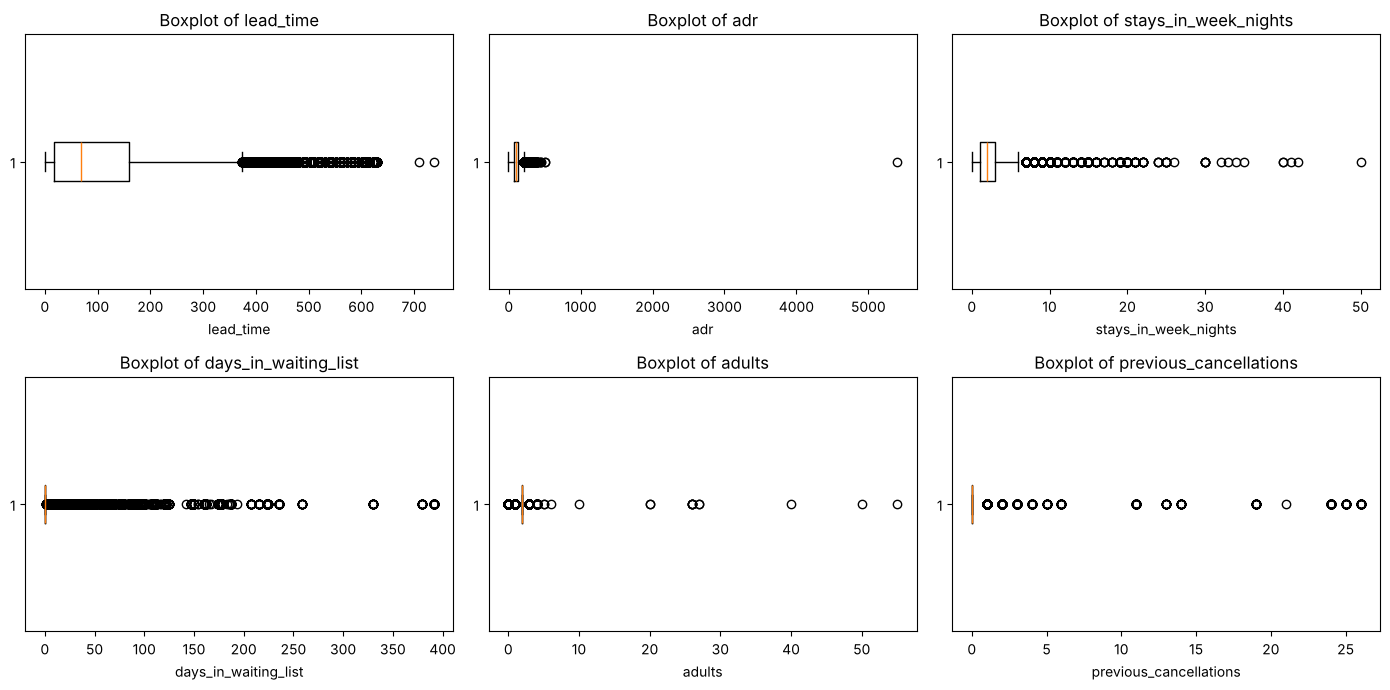

In [9]:
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax, c in zip(axes.ravel(), ["lead_time", "adr", "stays_in_week_nights",
                                "days_in_waiting_list", "adults", "previous_cancellations"]):
    ax.boxplot(df[c], vert=False)
    ax.set_title(f"Boxplot of {c}")
    ax.set_xlabel(c)
plt.tight_layout()
plt.show()

In [10]:
# Look closely at the values that look impossible rather than deleting by reflex.
print("Rows with adults > 10:", (df["adults"] > 10).sum())
print(df.loc[df["adults"] > 10, ["hotel", "adults", "children", "babies", "is_canceled"]].head(12))
print()
print("Rows with adr < 0:", (df["adr"] < 0).sum())
print("Five highest adr values:", df["adr"].nlargest(5).tolist())

Rows with adults > 10: 12
             hotel  adults  children  babies  is_canceled
1539  Resort Hotel      40       0.0       0            1
1587  Resort Hotel      26       0.0       0            1
1643  Resort Hotel      50       0.0       0            1
1752  Resort Hotel      26       0.0       0            1
1884  Resort Hotel      26       0.0       0            1
1917  Resort Hotel      27       0.0       0            1
1962  Resort Hotel      27       0.0       0            1
2003  Resort Hotel      26       0.0       0            1
2164  Resort Hotel      26       0.0       0            1
2173  Resort Hotel      55       0.0       0            1
2228  Resort Hotel      20       0.0       0            1
2418  Resort Hotel      20       0.0       0            1

Rows with adr < 0: 1
Five highest adr values: [5400.0, 510.0, 508.0, 451.5, 450.0]


**Verdict for each flagged column**

| Column | What we saw | Genuine or error? | Treatment |
|---|---|---|---|
| `adults` | 12 rows with 20–55 adults, no children or babies (all cancelled) | Error (group/block entries or typos) | **Remove** rows with `adults > 10`. All 12 are cancellations, so this slightly lowers the cancel rate; we accept that because 20–55 adults in one booking is not a normal reservation |
| `adr` | one negative price; one value of 5,400 while the next highest is 510 | Both errors | **Remove** `adr < 0` and `adr > 1000`. Other high prices (up to 510) are genuine peak-season or suite rates and are kept |
| `lead_time` | up to 737 days | Genuine (very early bookings) | **Keep**; the skew is handled by a log transform in Stage E |
| `stays_in_week_nights`, `stays_in_weekend_nights` | up to 50 and 19 | Plausible long stays | **Keep** |
| `days_in_waiting_list` | up to 391, most rows are 0 | Genuine | **Keep**; binned (Stage D) and log-transformed (Stage E) |
| `previous_cancellations`, `previous_bookings_not_canceled`, `children`, `babies`, `booking_changes`, `required_car_parking_spaces` | IQR is 0, so *every* non-zero value is flagged | Not errors, just zero-inflated counts where the rule is not meaningful | **Keep** |

## Rule-based cleaning (before the split)
These steps use fixed rules and learn nothing from the data, so doing them before the split cannot leak information.

1. **Remove the invalid rows** identified in Stage F.
2. **Drop the leakage columns** `reservation_status` and `reservation_status_date`. They record how the booking ended (e.g. "Canceled", "Check-Out"), which is not known when we would make a prediction. Keeping them would give a near-perfect but useless model.
3. **Drop exact duplicate rows.** Otherwise identical rows can land in both the training and test set and inflate the score. Side effect: the duplicates were mostly cancellations, so the class balance shifts towards "not cancelled".
4. **Drop columns that are not known at booking time or cannot generalise:** `assigned_room_type` (decided at check-in), `booking_changes` (counts changes made after booking) and `arrival_date_year` (the data only covers 2015–2017, so a future year would look like 2017).

In [11]:
d = df.copy()

n = len(d)
d = d[(d["adults"] <= 10) & (d["adr"] >= 0) & (d["adr"] <= 1000)]
print("Invalid rows removed:", n - len(d))

d = d.drop(columns=["reservation_status", "reservation_status_date"])

n = len(d)
d = d.drop_duplicates()
print("Exact duplicates removed:", n - len(d))

d = d.drop(columns=["assigned_room_type", "booking_changes", "arrival_date_year"])

df_clean = d.reset_index(drop=True)
print("Shape after cleaning:", df_clean.shape)
print((df_clean["is_canceled"].value_counts(normalize=True) * 100).round(2))

Invalid rows removed: 14
Exact duplicates removed: 32252
Shape after cleaning: (87124, 27)
is_canceled
0    72.74
1    27.26
Name: proportion, dtype: float64


## Train/test split
From here on, anything that *learns* from the data (an encoder, scaler, selector) is fitted on the training set only. We hold out 20% as a test set. `stratify=y` keeps the cancelled/not-cancelled ratio the same in both parts.

In [12]:
X = df_clean.drop(columns="is_canceled")
y = df_clean["is_canceled"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y)

print("Train:", X_train.shape, "Test:", X_test.shape)
print("Cancel rate  train: %.3f   test: %.3f" % (y_train.mean(), y_test.mean()))

Train: (69699, 26) Test: (17425, 26)
Cancel rate  train: 0.273   test: 0.273


## Stage B — Handling missing values
| Column | Missing | Strategy | Reason |
|---|---|---|---|
| `children` | 4 rows | Fill with **0** (constant) | Only 4 rows; no children is by far the most common value |
| `country` | ~0.4% | Fill with **"Unknown"** (constant) | The country was simply not recorded; we do not guess a real country |
| `agent` | ~14% | Fill with **0 / "no agent"** (constant), then treat as a category | Missing most likely means the booking did not go through an agent |
| `company` | ~94% | Replace with a **0/1 flag `has_company`** and drop the column | Too sparse to use the ID values, but "was a company involved?" is still informative |

Dropping rows was avoided because `agent` alone would remove ~14% of the data. All fills here are **constants**, so nothing is learned from the data and the same function can safely be applied to train and test. A mean/median/mode fill would have to be fitted on the training set first.

In [13]:
def handle_missing(d):
    d = d.copy()
    d["children"] = d["children"].fillna(0)
    d["country"] = d["country"].fillna("Unknown")
    # agent is an ID, so we keep it as text (a category), not a number
    d["agent"] = d["agent"].fillna(0).astype(int).astype(str)
    d["has_company"] = d["company"].notna().astype(int)
    return d.drop(columns="company")

before = X_train.isnull().sum()
X_train = handle_missing(X_train)
X_test = handle_missing(X_test)

print("Missing values in train, before:", int(before.sum()), "-> after:", int(X_train.isnull().sum().sum()))
print("Missing values in test after:", int(X_test.isnull().sum().sum()))

Missing values in train, before: 75648 -> after: 0
Missing values in test after: 0


## Stage C — Encoding categorical data
| Type | Columns | Scheme | Why |
|---|---|---|---|
| Binary | `hotel` | 0/1 mapping (City Hotel = 0, Resort Hotel = 1) | Only two values |
| Ordinal | `arrival_date_month` | Integer 1–12 in **calendar order**: January < February < ... < December | The months have a natural order. (They are really cyclical, December is next to January; we accept this simplification for a baseline.) |
| Ordinal | `meal` | **SC/Undefined = 0 < BB = 1 < HB = 2 < FB = 3** | Orders the board types by how many meals are included (none, breakfast, half board, full board) |
| Nominal | `deposit_type`, `market_segment`, `distribution_channel`, `customer_type`, `reserved_room_type`, `country`, `agent` | **One-hot encoding** | No natural order; integer codes would invent a fake one |

`country` and `agent` have many categories (hundreds). One-hot encoding all of them would create hundreds of mostly-empty columns, so categories seen in **less than 1% of training rows are grouped into one "infrequent" column**. The encoder is fitted on the training set only; unseen categories in the test set also fall into that group.

In [14]:
MONTH_ORDER = ["January", "February", "March", "April", "May", "June", "July",
               "August", "September", "October", "November", "December"]
MEAL_ORDER = {"Undefined": 0, "SC": 0, "BB": 1, "HB": 2, "FB": 3}

def encode_binary_ordinal(d):
    d = d.copy()
    d["hotel"] = d["hotel"].map({"City Hotel": 0, "Resort Hotel": 1})
    d["arrival_date_month"] = d["arrival_date_month"].map({m: i + 1 for i, m in enumerate(MONTH_ORDER)})
    d["meal"] = d["meal"].map(MEAL_ORDER)
    return d

nominal_cols = ["deposit_type", "market_segment", "distribution_channel", "customer_type",
                "reserved_room_type", "country", "agent"]

X_train = encode_binary_ordinal(X_train)
X_test = encode_binary_ordinal(X_test)

# Fit the one-hot encoder on TRAIN only, then transform both.
ohe = OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=0.01, sparse_output=False)
ohe.fit(X_train[nominal_cols])

def apply_ohe(d):
    enc = pd.DataFrame(ohe.transform(d[nominal_cols]),
                       columns=ohe.get_feature_names_out(nominal_cols), index=d.index)
    return pd.concat([d.drop(columns=nominal_cols), enc], axis=1)

X_train = apply_ohe(X_train)
X_test = apply_ohe(X_test)

print("Columns after encoding:", X_train.shape[1])
print("Any text columns left?", [c for c in X_train.columns if not pd.api.types.is_numeric_dtype(X_train[c])])

Columns after encoding: 72
Any text columns left? []


## Stage D — Binning / discretization
We use **domain-defined bins** (fixed boundaries we choose, so nothing is fitted) on three columns:

- `lead_time` into 6 bins: 0–7, 8–30, 31–90, 91–180, 181–365, 365+ days. The edges follow natural booking behaviour: last-minute, within a month, within a quarter, within half a year, within a year, more than a year ahead. The table below (training set) shows the cancellation rate rising steeply from the last-minute bin up to about half a year ahead and then levelling off. The 365+ bin is small and not higher than the bin before it, but we keep it separate because bookings made more than a year ahead are a distinct behaviour.
- `previous_cancellations` into 0, 1 and 2+. The table below shows a non-linear pattern: guests with exactly 1 previous cancellation cancel far more often than those with 0, but the 2+ group (very few bookings) falls back to a rate close to the 0 group. A straight-line relationship with the raw count would miss that, which is a good reason to bin.
- `days_in_waiting_list` into a flag: 0 (no wait) vs more than 0. The vast majority of rows are 0 and the exact length of a rare wait is not meaningful. The tables show this flag covers under 1% of bookings and only mildly changes the cancel rate, so we expect the selection stage to drop it, which is a useful check on whether the idea was worth keeping.

The original numeric columns are kept as well; the bins give the model step-shaped information, and the feature-selection stage (G) will remove whatever turns out to be redundant.

In [15]:
LEAD_EDGES = [-1, 7, 30, 90, 180, 365, np.inf]   # bin 0..5

def add_bins(d):
    d = d.copy()
    d["lead_time_bin"] = pd.cut(d["lead_time"], bins=LEAD_EDGES, labels=False).astype(int)
    d["prev_cancel_bin"] = pd.cut(d["previous_cancellations"], bins=[-1, 0, 1, np.inf], labels=False).astype(int)
    d["waiting_list_flag"] = (d["days_in_waiting_list"] > 0).astype(int)
    return d

X_train = add_bins(X_train)
X_test = add_bins(X_test)

# Evidence for the boundaries (training data only): cancellation rate and size per bin
check = pd.concat([X_train["lead_time_bin"], y_train], axis=1).groupby("lead_time_bin")["is_canceled"].agg(["mean", "count"])
check.index = ["0-7 d", "8-30 d", "31-90 d", "91-180 d", "181-365 d", "365+ d"]
check["mean"] = (check["mean"] * 100).round(1)
display(check.rename(columns={"mean": "cancel_rate_%", "count": "bookings"}))

for col, labels in [("prev_cancel_bin", ["0", "1", "2+"]), ("waiting_list_flag", ["0 days", "> 0 days"])]:
    t = pd.concat([X_train[col], y_train], axis=1).groupby(col)["is_canceled"].agg(["mean", "count"])
    t.index = labels
    t["mean"] = (t["mean"] * 100).round(1)
    display(t.rename(columns={"mean": "cancel_rate_%", "count": "bookings"}))

,cancel_rate_%,bookings
0-7 d,8.5,14653
8-30 d,25.3,13013
31-90 d,31.6,18156
91-180 d,34.7,14482
181-365 d,39.4,8946
365+ d,39.0,449


,cancel_rate_%,bookings
0,26.5,68362
1,75.4,1109
2+,27.2,228


,cancel_rate_%,bookings
0 days,27.2,69032
> 0 days,33.7,667


## Stage E — Scaling and transformation
**Log transform.** Count and money columns such as `lead_time`, `adr` and `days_in_waiting_list` are heavily right-skewed (many small values, a few huge ones). We apply `log1p` (log of 1 + x, which handles zeros) to every continuous column whose skewness on the **training set** is above 1. This pulls in the long tail so extreme values do not dominate.

**Scaling.** We standardise (mean 0, standard deviation 1) all numeric and ordinal columns with `StandardScaler`, fitted on the training set. Logistic Regression needs this because its coefficients and optimisation are sensitive to feature scale (`lead_time` goes to 737, `adults` to 4). Tree-based models like Random Forest do not need it, but it does no harm. The 0/1 flags and one-hot columns are left as they are.

In [16]:
continuous_cols = ["lead_time", "arrival_date_week_number", "arrival_date_day_of_month",
                   "stays_in_weekend_nights", "stays_in_week_nights", "adults", "children", "babies",
                   "previous_cancellations", "previous_bookings_not_canceled", "days_in_waiting_list",
                   "adr", "required_car_parking_spaces", "total_of_special_requests"]
ordinal_cols = ["arrival_date_month", "meal", "lead_time_bin", "prev_cancel_bin"]

skew_before = X_train[continuous_cols].skew()
log_cols = skew_before[skew_before > 1].index.tolist()   # chosen from TRAIN statistics only
print("Columns log-transformed:", log_cols)

raw_train = X_train[["lead_time", "adr"]].copy()          # kept only for the before/after plot
X_train[log_cols] = np.log1p(X_train[log_cols])
X_test[log_cols] = np.log1p(X_test[log_cols])

skew_table = pd.DataFrame({"skew_before": skew_before.round(2),
                           "skew_after": X_train[continuous_cols].skew().round(2)})
skew_table.loc[log_cols]

Columns log-transformed: ['lead_time', 'stays_in_weekend_nights', 'stays_in_week_nights', 'children', 'babies', 'previous_cancellations', 'previous_bookings_not_canceled', 'days_in_waiting_list', 'required_car_parking_spaces', 'total_of_special_requests']


,skew_before,skew_after
lead_time,1.43,-0.71
stays_in_weekend_nights,1.36,0.09
stays_in_week_nights,2.64,-0.16
children,3.49,3.05
babies,22.73,10.14
previous_cancellations,34.41,10.63
previous_bookings_not_canceled,20.45,6.96
days_in_waiting_list,19.78,10.83
required_car_parking_spaces,3.29,3.00
total_of_special_requests,1.08,0.44


**Reading the table.** The log transform fixes the clearly skewed measurement-like columns (`lead_time`, the number of nights). Columns that are mostly zeros (`babies`, `previous_cancellations`, `previous_bookings_not_canceled`, `days_in_waiting_list`) stay skewed afterwards, because a log cannot spread out a column where most values are 0. We accept that: they are zero-inflated counts, and tree-based models are not affected by skew anyway.

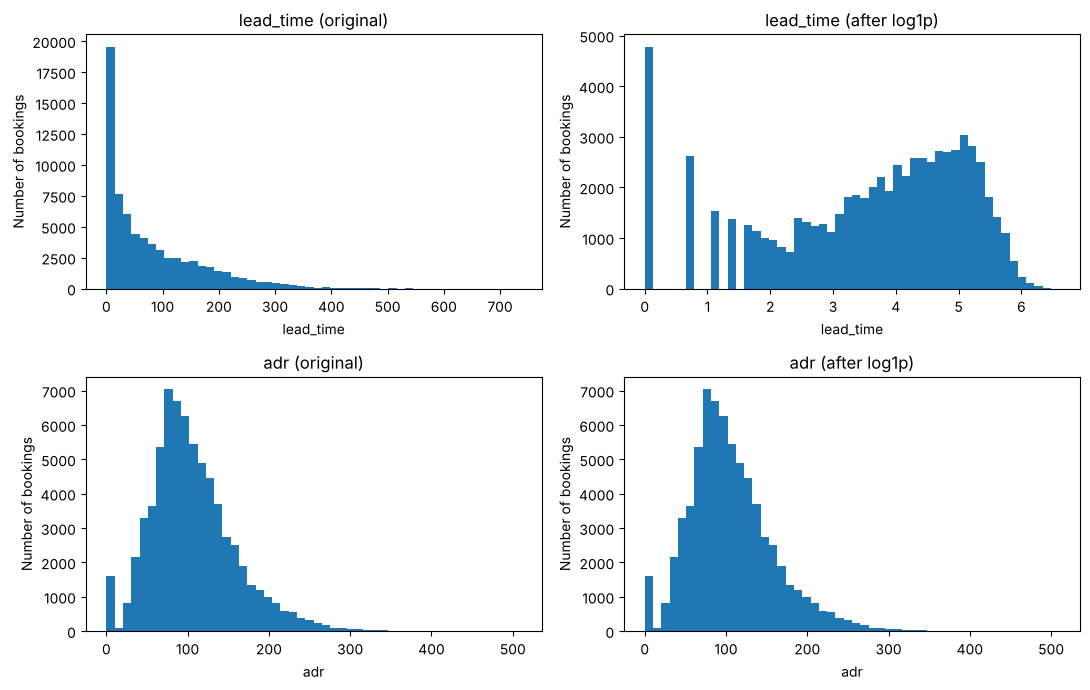

In [17]:
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for row, col in enumerate(["lead_time", "adr"]):
    axes[row, 0].hist(raw_train[col], bins=50)
    axes[row, 0].set_title(f"{col} (original)")
    axes[row, 1].hist(X_train[col], bins=50)
    axes[row, 1].set_title(f"{col} (after log1p)")
    for ax in axes[row]:
        ax.set_xlabel(col)
        ax.set_ylabel("Number of bookings")
plt.tight_layout()
plt.show()

In [18]:
scale_cols = continuous_cols + ordinal_cols
scaler = StandardScaler().fit(X_train[scale_cols])        # fitted on TRAIN only
X_train[scale_cols] = scaler.transform(X_train[scale_cols])
X_test[scale_cols] = scaler.transform(X_test[scale_cols])

# Check: train columns should now have mean ~0 and std ~1
X_train[scale_cols].describe().loc[["mean", "std"]].round(3)

,lead_time,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,previous_cancellations,previous_bookings_not_canceled,days_in_waiting_list,adr,required_car_parking_spaces,total_of_special_requests,arrival_date_month,meal,lead_time_bin,prev_cancel_bin
mean,0.0,0.0,0.0,0.0,-0.0,0.0,0.0,-0.0,-0.0,-0.0,0.0,0.0,0.0,-0.0,0.0,-0.0,0.0,-0.0
std,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0


## Stage G — Dimensionality reduction (feature selection)
After encoding we have many columns, and some are redundant or uninformative. We apply three feature-selection filters in sequence, all fitted on the **training set**:

1. **Variance threshold** removes columns that are almost constant (variance below 0.01); they cannot help separate the classes.
2. **Correlation filter** removes one column of every pair with correlation above 0.9; two near-identical columns add no new information (e.g. week number vs month).
3. **Model-based importance**: a Random Forest is trained and we keep the features with importance above the median.

We chose feature *selection* rather than PCA because it keeps the original column names, so we can still explain which booking details drive the prediction.

In [19]:
n_original = df.shape[1] - 1          # raw columns excluding the target
n_after_cleaning = X.shape[1]         # after dropping leakage / not-known-at-booking columns
n_encoded = X_train.shape[1]          # after missing-value handling, encoding and binning
print("Original feature columns:", n_original)
print("After cleaning:", n_after_cleaning)
print("After encoding + binning:", n_encoded)

Original feature columns: 31
After cleaning: 26
After encoding + binning: 75


In [20]:
# 1) Variance threshold
vt = VarianceThreshold(threshold=0.01).fit(X_train)
dropped_var = X_train.columns[~vt.get_support()].tolist()
keep_var = X_train.columns[vt.get_support()].tolist()
print("Removed by variance threshold:", dropped_var)

# 2) Correlation filter
corr = X_train[keep_var].corr().abs()
upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
pairs = [(a, b, round(float(upper.loc[a, b]), 3)) for b in upper.columns for a in upper.index
         if upper.loc[a, b] > 0.9]
dropped_corr = sorted({b for _, b, _ in pairs})
keep_corr = [c for c in keep_var if c not in dropped_corr]
print("Highly correlated pairs (r > 0.9):", pairs)
print("Removed by correlation filter:", dropped_corr)

Removed by variance threshold: ['deposit_type_infrequent_sklearn', 'distribution_channel_infrequent_sklearn', 'customer_type_infrequent_sklearn', 'reserved_room_type_infrequent_sklearn', 'waiting_list_flag']


Highly correlated pairs (r > 0.9): [('arrival_date_month', 'arrival_date_week_number', 0.995), ('deposit_type_No Deposit', 'deposit_type_Non Refund', 0.95), ('market_segment_Direct', 'distribution_channel_Direct', 0.916), ('lead_time', 'lead_time_bin', 0.938), ('previous_cancellations', 'prev_cancel_bin', 0.968)]
Removed by correlation filter: ['arrival_date_week_number', 'deposit_type_Non Refund', 'distribution_channel_Direct', 'lead_time_bin', 'prev_cancel_bin']


                              stage  n_features
                   Original columns          31
                     After cleaning          26
           After encoding + binning          75
           After variance threshold          70
           After correlation filter          65
After model-based selection (final)          33

Top 10 features by importance:
lead_time                      0.150
country_PRT                    0.092
total_of_special_requests      0.088
adr                            0.078
required_car_parking_spaces    0.051
arrival_date_day_of_month      0.051
arrival_date_month             0.041
agent_9                        0.040
stays_in_week_nights           0.038
market_segment_Online TA       0.038


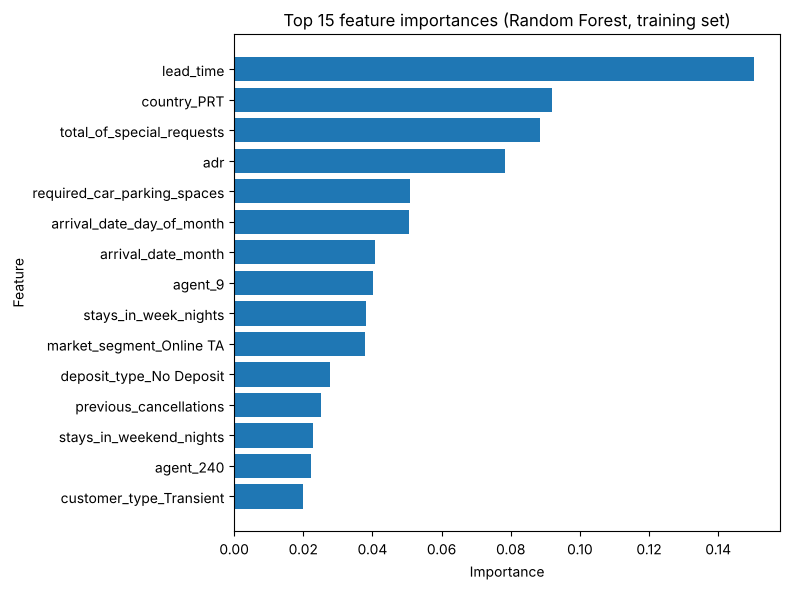

In [21]:
# 3) Model-based importance (Random Forest, keep features above the median importance)
rf_sel = RandomForestClassifier(n_estimators=100, min_samples_leaf=3, n_jobs=-1,
                                random_state=RANDOM_STATE).fit(X_train[keep_corr], y_train)
sfm = SelectFromModel(rf_sel, threshold="median", prefit=True)
selected = [c for c, keep in zip(keep_corr, sfm.get_support()) if keep]

summary = pd.DataFrame({"stage": ["Original columns", "After cleaning", "After encoding + binning",
                                  "After variance threshold", "After correlation filter",
                                  "After model-based selection (final)"],
                        "n_features": [n_original, n_after_cleaning, n_encoded,
                                       len(keep_var), len(keep_corr), len(selected)]})
print(summary.to_string(index=False))

imp = pd.Series(rf_sel.feature_importances_, index=keep_corr).sort_values().tail(15)
print()
print("Top 10 features by importance:")
print(imp.sort_values(ascending=False).head(10).round(3).to_string())
plt.figure(figsize=(8, 6))
plt.barh(imp.index, imp.values)
plt.title("Top 15 feature importances (Random Forest, training set)")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

**Result.** We went from 31 raw feature columns to 26 after cleaning, 75 after encoding and binning, 70 after the variance threshold, 65 after the correlation filter and **33 in the final set**.

- The variance filter dropped `waiting_list_flag` (as expected) and several rare 'infrequent' grouping columns.
- The correlation filter dropped near-duplicates: `arrival_date_week_number` (r = 0.995 with the month), `lead_time_bin` (r = 0.94 with `lead_time`) and `prev_cancel_bin` (r = 0.97 with `previous_cancellations`). So the binned columns added no information beyond the raw columns for these models; binning is still useful for interpretation and for models that cannot cope with skew.
- As a sanity check, `lead_time` and the number of special requests rank near the top of the importance list, matching what the exploration showed.

## Stage H — Model training and evaluation
We train two models on the preprocessed, feature-selected training data and evaluate them once on the untouched test set:

- **Logistic Regression**: a simple, interpretable baseline.
- **Random Forest**: a more flexible model that can capture interactions between features.

Accuracy alone is misleading here (always predicting "not cancelled" already scores about 73% after duplicate removal), so we also report precision, recall, F1 and ROC-AUC for the cancelled class.

In [22]:
Xtr, Xte = X_train[selected], X_test[selected]

models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Random Forest": RandomForestClassifier(n_estimators=100, min_samples_leaf=3, n_jobs=-1,
                                            random_state=RANDOM_STATE),
}
results, fitted = [], {}
for name, model in models.items():
    model.fit(Xtr, y_train)
    pred = model.predict(Xte)
    proba = model.predict_proba(Xte)[:, 1]
    fitted[name] = pred
    results.append({"model": name,
                    "accuracy": accuracy_score(y_test, pred),
                    "precision": precision_score(y_test, pred),
                    "recall": recall_score(y_test, pred),
                    "f1": f1_score(y_test, pred),
                    "roc_auc": roc_auc_score(y_test, proba)})

print("Always-predict-'not cancelled' accuracy:", round((y_test == 0).mean(), 3))
pd.DataFrame(results).set_index("model").round(3)

Always-predict-'not cancelled' accuracy: 0.727


,accuracy,precision,recall,f1,roc_auc
model,,,,,
Logistic Regression,0.803,0.677,0.528,0.593,0.856
Random Forest,0.838,0.746,0.617,0.675,0.901


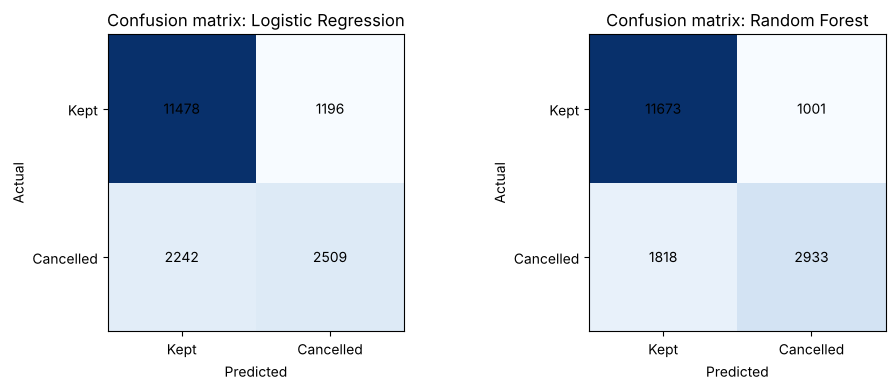

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, (name, pred) in zip(axes, fitted.items()):
    cm = confusion_matrix(y_test, pred)
    ax.imshow(cm, cmap="Blues")
    for i in range(2):
        for j in range(2):
            ax.text(j, i, cm[i, j], ha="center", va="center")
    ax.set_xticks([0, 1], ["Kept", "Cancelled"])
    ax.set_yticks([0, 1], ["Kept", "Cancelled"])
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")
    ax.set_title(f"Confusion matrix: {name}")
plt.tight_layout()
plt.show()

**What we learned**

- Both models beat the "always predict not cancelled" baseline, which confirms the preprocessing produced useful features.
- Random Forest scores higher than Logistic Regression, which suggests interactions between features matter (e.g. long lead time combined with no deposit).
- Recall for the cancelled class is the weak spot: some real cancellations are missed because the default decision threshold of 0.5 favours the majority class.
- The train/test split happened before every fitted step (encoder, scaler, variance filter, correlation filter, importance selector), so the test score is not inflated by leakage.

## Summary of preprocessing decisions

In [24]:
decisions = pd.DataFrame([
    ["F", "Outlier removal (domain rules)", "adults, adr", "20-55 adults and negative/5,400 prices are errors; other extremes are genuine and kept"],
    ["Cleaning", "Drop leakage columns", "reservation_status, reservation_status_date", "Describe the final outcome; not known at prediction time"],
    ["Cleaning", "Drop not-known-at-booking / non-generalising columns", "assigned_room_type, booking_changes, arrival_date_year", "Decided after booking, or data covers only 2015-2017"],
    ["Cleaning", "Drop exact duplicates", "all columns", "Prevents identical rows appearing in both train and test"],
    ["B", "Constant imputation", "children, country, agent", "Missing means 'none / not recorded'; constants learn nothing from data"],
    ["B", "Missing flag + drop column", "company", "94% missing; 'has company' keeps the useful signal"],
    ["C", "Binary mapping", "hotel", "Two values"],
    ["C", "Ordinal encoding (order stated)", "arrival_date_month, meal", "Calendar order; number of meals included"],
    ["C", "One-hot encoding (rare categories grouped)", "deposit_type, market_segment, distribution_channel, customer_type, reserved_room_type, country, agent", "No natural order; grouping keeps column count manageable"],
    ["D", "Domain-defined binning / flag", "lead_time, previous_cancellations, days_in_waiting_list", "Meaningful ranges; rare large values grouped"],
    ["E", "log1p transform", "columns with train skewness > 1", "Reduces right skew"],
    ["E", "StandardScaler", "numeric and ordinal columns", "Needed for Logistic Regression"],
    ["G", "Variance threshold, correlation filter, RF importance", "all encoded columns", "Remove constant, redundant and weak features"],
    ["H", "Stratified 80/20 split before any fitting", "-", "Avoids data leakage"],
], columns=["Stage", "Technique", "Columns", "Reason"])
decisions

,Stage,Technique,Columns,Reason
0,F,Outlier removal (domain rules),"adults, adr","20-55 adults and negative/5,400 prices are errors; other extremes are genuine and kept"
1,Cleaning,Drop leakage columns,"reservation_status, reservation_status_date",Describe the final outcome; not known at prediction time
2,Cleaning,Drop not-known-at-booking / non-generalising columns,"assigned_room_type, booking_changes, arrival_date_year","Decided after booking, or data covers only 2015-2017"
3,Cleaning,Drop exact duplicates,all columns,Prevents identical rows appearing in both train and test
4,B,Constant imputation,"children, country, agent",Missing means 'none / not recorded'; constants learn nothing from data
5,B,Missing flag + drop column,company,94% missing; 'has company' keeps the useful signal
6,C,Binary mapping,hotel,Two values
7,C,Ordinal encoding (order stated),"arrival_date_month, meal",Calendar order; number of meals included
8,C,One-hot encoding (rare categories grouped),"deposit_type, market_segment, distribution_channel, customer_type, reserved_room_type, country, agent",No natural order; grouping keeps column count manageable
9,D,Domain-defined binning / flag,"lead_time, previous_cancellations, days_in_waiting_list",Meaningful ranges; rare large values grouped


## Sources and AI assistance
- Dataset: *Hotel Booking Demand*, Antonio, Almeida and Nunes (2019), Kaggle / Data in Brief.
- pandas, NumPy, scikit-learn and Matplotlib documentation, for the API usage of `OneHotEncoder`, `StandardScaler`, `VarianceThreshold`, `SelectFromModel` and `train_test_split`.
- AI assistant (Claude, by Anthropic): used to discuss the preprocessing plan, to help draft and debug the code, and to draft the explanatory text. All team members have reviewed the notebook and can explain every step. *(Edit this note to describe your own use accurately.)*